---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 1"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 1. Підсилювачі. Основні параметри та характеристики</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>1.1. Підсилювачі. Основні визначення, класифікація та параметри підсилювачів</li>
  <li>1.2. Частотні характеристики підсилювачів</li>
  <li>1.3. Амплітудні характеристики підсилювачів</li>
  <li>1.4. Енергетичні характеристики підсилювачів</li>
  <li>1.5. Імпульсні і перехідні характеристики підсилювачів</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 1 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Підсилювачі. Основні визначення, класифікація та параметри](#amp-basics)
    * [🔬 Інтерактивно: вплив опорів джерела і навантаження](#kskv-interactive)
* [Частотні характеристики підсилювачів](#freq-response)
    * [🔬 Інтерактивно: АЧХ і ФЧХ підсилювача змінного струму](#bode-interactive)
* [Амплітудні характеристики підсилювачів](#amp-char)
    * [🔬 Інтерактивно: амплітудна характеристика і спектр вихідного сигналу](#thd-interactive)
* [Енергетичні характеристики підсилювачів](#energy)
    * [🔬 Інтерактивно: форма струму підсилювального елемента в різних класах](#classes-interactive)
* [Імпульсні і перехідні характеристики підсилювачів](#transient)
    * [🔬 Інтерактивно: перехідна характеристика і передача прямокутного імпульсу](#step-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Підсилювачі. Основні визначення, класифікація та параметри <a class="anchor" id="amp-basics"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.1</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснити принцип підсилення як керованої передачі енергії джерела живлення в навантаження
> - Класифікувати підсилювачі за смугою частот, видом сигналу, призначенням і елементною базою
> - Розраховувати коефіцієнти підсилення за напругою, струмом і потужністю, у тому числі в децибелах
> - Враховувати вплив опору джерела сигналу і навантаження через вхідний і вихідний опори підсилювача

</div>

### Основні визначення

**Підсилювач** — пристрій, який за рахунок енергії джерела живлення збільшує потужність вхідного сигналу, зберігаючи (з допустимими спотвореннями) його форму, тобто інформацію, що в ньому міститься.

**Принцип підсилення.** Підсилювальний елемент (транзистор, лампа, інтегральна мікросхема) працює як *керований опір*: слабкий вхідний сигнал керує потоком енергії від джерела живлення $E_ж$ до навантаження $R_н$. Тому потужність у навантаженні може бути значно більшою від потужності, яку віддає джерело сигналу, — енергія береться не з сигналу, а з джерела живлення.

**Спотворення** — будь-яка зміна форми сигналу, тобто втрата частини інформації або поява нової (наприклад, гармонік, яких не було у вхідному сигналі). Будь-яке реальне підсилення супроводжується спотвореннями; завдання схемотехніка — утримати їх у допустимих межах.

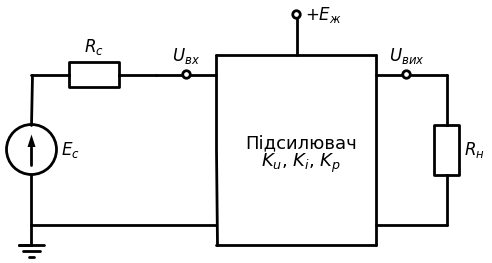

In [2]:
# Структурна схема: джерело сигналу -> підсилювач -> навантаження, живлення від E_ж
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2.5) as d:
        d += EMF().at((0, 0)).up(3).label('$E_c$', loc='bottom')
        d += elm.Resistor().at((0, 3)).right(2.5).label('$R_c$')
        d += elm.Line().right(0.6)
        d += elm.Dot(open=True).label('$U_{вх}$', loc='top')
        d += elm.Line().right(0.6)
        x0, x1 = 3.7, 6.9                                    # межі «чорної скриньки» підсилювача
        d += elm.Line().at((x0, -0.4)).to((x1, -0.4))
        d += elm.Line().at((x1, -0.4)).to((x1, 3.4))
        d += elm.Line().at((x1, 3.4)).to((x0, 3.4))
        d += elm.Line().at((x0, 3.4)).to((x0, -0.4))
        d += elm.Label().at(((x0 + x1) / 2, 1.5)).label('Підсилювач\n$K_u$, $K_i$, $K_p$', fontsize=13)
        d += elm.Line().at(((x0 + x1) / 2, 3.4)).up(0.8)
        d += elm.Dot(open=True).label('$+E_ж$', loc='right')
        d += elm.Line().at((x1, 3)).right(0.6)
        d += elm.Dot(open=True).label('$U_{вих}$', loc='top')
        d += elm.Line().right(0.8)
        d += elm.Resistor().down(3).label('$R_н$', loc='bottom')
        d += elm.Line().left().tox(x1)
        d += elm.Line().at((0, 0)).right().tox(x0)
        d += elm.Ground().at((0, 0))

### Класифікація підсилювачів

| Ознака | Види | Пояснення |
|---|---|---|
| Смуга частот | **підсилювачі постійного струму (ППС)** | підсилюють від $f_н = 0$ до $f_в$; з ППС можна отримати будь-який інший тип |
| | **підсилювачі змінного струму (низької частоти, ПНЧ)** | $f_н \neq 0$, $f_в \gg f_н$ (звукові: 20 Гц…20 кГц) |
| | **широкосмугові (відео-, імпульсні)** | $f_в/f_н \sim 10^4\ldots10^6$, нормується ФЧХ і перехідна характеристика |
| | **вибіркові (резонансні, ПВЧ)** | вузька смуга навколо $f_0$: $\Delta f \ll f_0$, $f_0 > 100$ кГц; навантаження — LC-контур |
| Вид сигналу | неперервних (гармонічних) сигналів; імпульсних сигналів | для імпульсних особливо важлива відсутність фазових спотворень |
| Призначення | підсилювачі **напруги**, **струму**, **потужності** | різняться вимогами до $R_{вх}$ і $R_{вих}$ (див. нижче) |
| Елементна база | лампові, транзисторні (БТ, ПТ), на інтегральних мікросхемах (ОП), магнітні, параметричні, квантові | |
| Спосіб підсилення | без перетворення спектра; з перетворенням спектра (супергетеродинний тракт, модулятор-демодулятор) | |
| Кількість каскадів | однокаскадні, багатокаскадні | див. тему 2 |

**Вимоги до опорів за призначенням:**
- **підсилювач напруги** — $R_{вх} \gg R_c$, $R_{вих} \ll R_н$ (бере мінімум струму від джерела і є «ідеальним джерелом напруги» для навантаження);
- **підсилювач струму** — $R_{вх} \ll R_c$, $R_{вих} \gg R_н$;
- **підсилювач потужності** — узгодження: $R_{вх} \approx R_c$, $R_{вих} \approx R_н$ (максимум переданої потужності).

### Підсилювач як чотириполюсник. Основні параметри

Підсилювач має два вхідні та два вихідні затискачі, тож його можна описати як **активний чотириполюсник**. Для малих сигналів зручно використовувати схему заміщення: вхід — опір $R_{вх}$, вихід — джерело ЕРС $K_{u0}U_{вх}$ (коефіцієнт підсилення *в режимі холостого ходу*) з внутрішнім опором $R_{вих}$.

**Коефіцієнти підсилення:**
$$K_u = \frac{U_{вих}}{U_{вх}},\qquad K_i = \frac{I_{вих}}{I_{вх}},\qquad K_p = \frac{P_{вих}}{P_{вх}} = K_u K_i .$$

У логарифмічних одиницях (децибелах):
$$K_u[\text{дБ}] = 20\lg K_u,\qquad K_i[\text{дБ}] = 20\lg K_i,\qquad K_p[\text{дБ}] = 10\lg K_p .$$
Перевага децибелів — коефіцієнти послідовно ввімкнених каскадів **додаються**, а не множаться.

**Вхідний і вихідний опори:** $R_{вх} = U_{вх}/I_{вх}$; $\;R_{вих} = -\Delta U_{вих}/\Delta I_{вих}$ (при $E_c = 0$) — визначає, наскільки «просідає» вихідна напруга при зміні навантаження.

**Наскрізний коефіцієнт підсилення** (від ЕРС джерела до навантаження) враховує два подільники напруги — на вході і на виході:
$$K_{скв} = \frac{U_{вих}}{E_c} = \frac{R_{вх}}{R_c + R_{вх}}\cdot K_{u0}\cdot\frac{R_н}{R_{вих} + R_н}.$$

Інші параметри: смуга пропускання $f_н\ldots f_в$, коефіцієнт гармонік $K_г$, динамічний діапазон $D$, номінальна вихідна потужність, ККД, коефіцієнт шуму, чутливість (вхідна напруга, яка забезпечує номінальну вихідну потужність). Вони розглядаються нижче.

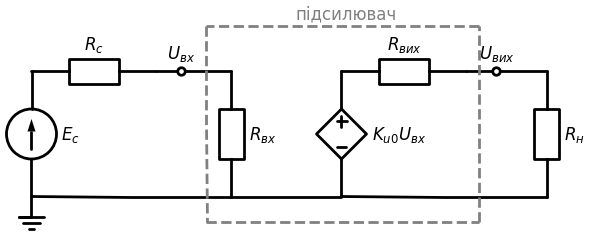

In [3]:
# Схема заміщення підсилювача як чотириполюсника (штрихова рамка — сам підсилювач)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2.5) as d:
        d += EMF().at((0, 0)).to((0, 2.5)).label('$E_c$', loc='bottom')
        d += elm.Resistor().at((0, 2.5)).to((2.5, 2.5)).label('$R_c$')
        d += elm.Line().to((3.0, 2.5))
        d += elm.Dot(open=True).label('$U_{вх}$', loc='top')
        d += elm.Line().to((4.0, 2.5))
        d += elm.Resistor().at((4.0, 2.5)).to((4.0, 0)).label('$R_{вх}$', loc='bottom')
        d += elm.Line().at((4.0, 0)).to((0, 0))
        d += elm.Line().at((4.0, 0)).to((6.2, 0))
        d += elm.SourceControlledV().at((6.2, 0)).to((6.2, 2.5)).label('$K_{u0}U_{вх}$', loc='bottom')
        d += elm.Resistor().at((6.2, 2.5)).to((8.7, 2.5)).label('$R_{вих}$')
        d += elm.Line().to((9.3, 2.5))
        d += elm.Dot(open=True).label('$U_{вих}$', loc='top')
        d += elm.Line().to((10.3, 2.5))
        d += elm.Resistor().at((10.3, 2.5)).to((10.3, 0)).label('$R_н$', loc='bottom')
        d += elm.Line().at((10.3, 0)).to((6.2, 0))
        d += elm.Ground().at((0, 0))
        for p1, p2 in [((3.5, -0.5), (8.95, -0.5)), ((8.95, -0.5), (8.95, 3.4)), ((8.95, 3.4), (3.5, 3.4)), ((3.5, 3.4), (3.5, -0.5))]:
            d += elm.Line().at(p1).to(p2).linestyle('--').color('gray')
        d += elm.Label().at((6.2, 3.75)).label('підсилювач', color='gray')

---
### 🔬 Інтерактивно: вплив опорів джерела і навантаження <a class="anchor" id="kskv-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Змінюйте опір джерела $R_c$, опір навантаження $R_н$, вхідний і вихідний опори підсилювача. Графік показує, яка частка коефіцієнта $K_{u0}$ «губиться» у вхідному та вихідному подільниках. Переконайтеся: для підсилювача напруги потрібно $R_{вх} \gg R_c$ і $R_{вих} \ll R_н$.

</div>

In [4]:
# Наскрізний коефіцієнт підсилення з урахуванням R_c, R_вх, R_вих, R_н
def k_through(Ku0=100.0, Rc_k=10.0, Rin_k=50.0, Rout_k=1.0, Rl_k=2.0):
    a_in = Rin_k / (Rc_k + Rin_k)
    a_out = Rl_k / (Rout_k + Rl_k)
    K = Ku0 * a_in * a_out
    fig, ax = plt.subplots(figsize=(8, 3.6))
    names = ['$K_{u0}$', 'після вхідного\nподільника', 'наскрізний\n$K_{скв}$']
    vals = [Ku0, Ku0 * a_in, K]
    bars = ax.bar(names, vals, color=['#2196F3', '#FF9800', '#4CAF50'])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.1f}\n({20*np.log10(v):.1f} дБ)', ha='center', va='bottom')
    ax.set_ylim(0, Ku0 * 1.3); ax.set_ylabel('Коефіцієнт підсилення')
    ax.set_title(f'Вхідний подільник: {a_in:.2f},  вихідний подільник: {a_out:.2f}')
    plt.tight_layout(); plt.show()
    print(f'K_скв = {Ku0} · {a_in:.3f} · {a_out:.3f} = {K:.2f}  ({20*np.log10(K):.1f} дБ)')

interact(k_through,
         Ku0=widgets.FloatSlider(min=10, max=1000, step=10, value=100, description='$K_{u0}$'),
         Rc_k=widgets.FloatSlider(min=0.1, max=100, step=0.1, value=10, description='Rc (кОм)'),
         Rin_k=widgets.FloatSlider(min=0.1, max=200, step=0.1, value=50, description='Rвх (кОм)'),
         Rout_k=widgets.FloatSlider(min=0.01, max=20, step=0.01, value=1, description='Rвих (кОм)'),
         Rl_k=widgets.FloatSlider(min=0.1, max=50, step=0.1, value=2, description='Rн (кОм)'));

interactive(children=(FloatSlider(value=100.0, description='$K_{u0}$', max=1000.0, min=10.0, step=10.0), Float…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Не плутайте $20\lg$ і $10\lg$.** Для напруги і струму $K[\text{дБ}] = 20\lg K$, бо потужність пропорційна *квадрату* напруги чи струму. Для потужності — $10\lg K_p$. Підсилення за напругою в 10 разів — це 20 дБ, а не 10 дБ. Значення $K_p[\text{дБ}]$ збігається з $K_u[\text{дБ}]$ лише тоді, коли $R_{вх} = R_н$.

</div>

---

## Частотні характеристики підсилювачів <a class="anchor" id="freq-response"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.2</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснити, які елементи схеми обмежують смугу пропускання знизу та зверху
> - Будувати АЧХ і ФЧХ у логарифмічному масштабі (діаграми Боде)
> - Визначати нижню і верхню граничні частоти, смугу пропускання, коефіцієнти частотних спотворень

</div>

Коефіцієнт підсилення реального підсилювача залежить від частоти, тому його записують у комплексній формі:
$$\dot K(j\omega) = K(\omega)\,e^{j\varphi(\omega)},$$
де $K(\omega) = |\dot K(j\omega)|$ — **амплітудно-частотна характеристика (АЧХ)**, $\varphi(\omega) = \arg \dot K(j\omega)$ — **фазочастотна характеристика (ФЧХ)**.

**Причини спаду АЧХ:**
- на **низьких частотах** — розділювальні конденсатори $C_р$ і блокувальні конденсатори в колах емітера/витоку $C_е$: їхній опір $1/(\omega C)$ зростає зі зниженням частоти; у ППС цих конденсаторів немає, тому $f_н = 0$;
- на **високих частотах** — інерційність підсилювального елемента (зниження $h_{21е}$ з частотою, ємності переходів, ефект Міллера) і паразитні ємності монтажу та навантаження $C_н$.

Для типового каскаду змінного струму АЧХ добре описується добутком ФВЧ першого порядку (нижня частота) і ФНЧ першого порядку (верхня частота):
$$\dot K(j\omega) = K_0\cdot\frac{j\omega\tau_н}{1 + j\omega\tau_н}\cdot\frac{1}{1 + j\omega\tau_в},\qquad f_н = \frac{1}{2\pi\tau_н},\quad f_в = \frac{1}{2\pi\tau_в}.$$

**Параметри АЧХ:**
- $K_0$ — коефіцієнт підсилення на середніх частотах (у смузі пропускання);
- **коефіцієнти частотних спотворень** $M_н = K_0/K_н$ і $M_в = K_0/K_в$ (у літературі також використовують обернене відношення $K/K_0$); у децибелах $M[\text{дБ}] = 20\lg M$;
- **граничні частоти** $f_н$, $f_в$ — частоти, на яких $K = K_0/\sqrt2$, тобто $M = \sqrt2$ (3 дБ);
- **смуга пропускання** $\Delta f = f_в - f_н$.

На граничних частотах фазовий зсув одноланкової моделі дорівнює $+45°$ (на $f_н$) і $-45°$ (на $f_в$); на середніх частотах $\varphi = 0$ (або $180°$ для інвертувального каскаду).

**Логарифмічна АЧХ (діаграма Боде):** по осі частот — $\lg f$, по осі підсилення — дБ. Кожна ланка першого порядку дає асимптоту з нахилом **±20 дБ/декаду** (±6 дБ/октаву); реальна крива відхиляється від асимптот на 3 дБ у точці зламу.

**Фазові спотворення** відсутні, якщо ФЧХ лінійна: $\varphi(\omega) = -\omega t_з$ — тоді всі гармоніки затримуються на однаковий час $t_з$ (*групова затримка* $t_{гр} = -d\varphi/d\omega$ стала).

---
### 🔬 Інтерактивно: АЧХ і ФЧХ підсилювача змінного струму <a class="anchor" id="bode-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Змінюйте $K_0$, $f_н$ і $f_в$. Пунктирні лінії — асимптоти ±20 дБ/дек; на граничних частотах АЧХ нижча за $K_0$ на 3 дБ, а фаза дорівнює ±45°. Встановіть $f_н$ у мінімум — так виглядає АЧХ підсилювача постійного струму.

</div>

In [5]:
# АЧХ і ФЧХ: добуток ФВЧ (f_н) і ФНЧ (f_в) першого порядку
def bode_amp(K0_dB=40.0, fn=50.0, fv_kHz=20.0):
    f = np.logspace(0, 7, 1200)
    fv = fv_kHz * 1e3
    K0 = 10 ** (K0_dB / 20)
    K = K0 * (1j * f / fn) / (1 + 1j * f / fn) / (1 + 1j * f / fv)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
    a1.semilogx(f, db(K), color='#2196F3', label='АЧХ')
    asym = np.where(f < fn, K0_dB + 20 * np.log10(f / fn), K0_dB) - np.where(f > fv, 20 * np.log10(f / fv), 0)
    a1.semilogx(f, asym, 'k--', lw=1, label='асимптоти ±20 дБ/дек')
    a1.axhline(K0_dB - 3, color='#FF9800', ls=':', label='$K_0$ − 3 дБ')
    for fx in (fn, fv):
        a1.axvline(fx, color='#F44336', ls='--', lw=1)
    a1.set_ylim(K0_dB - 50, K0_dB + 8); a1.set_ylabel('K, дБ'); a1.legend(loc='lower center')
    a1.set_title(f'Смуга пропускання: {fn:.0f} Гц … {fv/1e3:.1f} кГц')
    a2.semilogx(f, np.degrees(np.angle(K)), color='#FF9800')
    for fx in (fn, fv):
        a2.axvline(fx, color='#F44336', ls='--', lw=1)
    a2.set_yticks([-90, -45, 0, 45, 90]); a2.set_ylabel('φ, град'); a2.set_xlabel('Частота, Гц')
    plt.tight_layout(); plt.show()
    print(f'На f_н: K = {db(K[np.argmin(abs(f-fn))]):.1f} дБ, φ = {np.degrees(np.angle(K0*(1j)/(1+1j)/(1+1j*fn/fv))):.1f}°;  '
          f'на f_в: φ = {np.degrees(np.angle(K0*(1j*fv/fn)/(1+1j*fv/fn)/(1+1j))):.1f}°')

interact(bode_amp,
         K0_dB=widgets.FloatSlider(min=0, max=80, step=1, value=40, description='K₀ (дБ)'),
         fn=widgets.FloatLogSlider(base=10, min=0, max=3, step=0.05, value=50, description='fн (Гц)'),
         fv_kHz=widgets.FloatLogSlider(base=10, min=0, max=3, step=0.05, value=20, description='fв (кГц)'));

interactive(children=(FloatSlider(value=40.0, description='K₀ (дБ)', max=80.0, step=1.0), FloatLogSlider(value…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**«Смуга пропускання» — не те саме, що «діапазон частот, де підсилювач працює».** За межами $f_н\ldots f_в$ підсилювач теж підсилює, але з помітними частотними спотвореннями. Межа $-3$ дБ — умовна: для аудіотехніки часто нормують нерівномірність АЧХ ±0,5 дБ або ±1 дБ, що дає вужчу смугу, ніж за рівнем −3 дБ.

</div>

---

## Амплітудні характеристики підсилювачів <a class="anchor" id="amp-char"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.3</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснити вигляд амплітудної характеристики та причини її нелінійності
> - Визначати динамічний діапазон підсилювача
> - Розраховувати коефіцієнт гармонік та пояснювати інтермодуляційні спотворення
> - Розрізняти власні шуми і завади, оцінювати відношення сигнал/шум

</div>

**Амплітудна характеристика** — залежність амплітуди (діючого значення) вихідної напруги від вхідної на фіксованій частоті в смузі пропускання: $U_{вих} = f(U_{вх})$.

Характерні ділянки:
1. **$U_{вх} \to 0$** — на виході залишається напруга власних шумів і завад $U_{ш}$; сигнал, менший за рівень шуму, виділити неможливо;
2. **лінійна ділянка** — $U_{вих} = K_0 U_{вх}$; це робоча ділянка;
3. **ділянка насичення (обмеження)** — вихідна напруга не може перевищити $U_{вих.max}$, яка обмежується напругою живлення та залишковими напругами на транзисторах.

**Динамічний діапазон** — відношення максимальної і мінімальної вхідних напруг, між якими підсилювач працює з допустимими спотвореннями:
$$D = \frac{U_{вх.max}}{U_{вх.min}},\qquad D[\text{дБ}] = 20\lg\frac{U_{вх.max}}{U_{вх.min}}.$$
$U_{вх.min}$ зазвичай вибирають у 2…5 разів більшою від приведеного до входу шуму, а $U_{вх.max}$ — за допустимим коефіцієнтом гармонік.

### Нелінійні спотворення

Через кривизну амплітудної характеристики синусоїдний вхідний сигнал на виході містить гармоніки $2f, 3f, \ldots$. Їх оцінюють **коефіцієнтом гармонік** (коефіцієнтом нелінійних спотворень):
$$K_г = \frac{\sqrt{U_2^2 + U_3^2 + U_4^2 + \dots}}{U_1}\cdot 100\%,$$
де $U_1$ — амплітуда першої (основної) гармоніки, $U_k$ — амплітуди вищих гармонік. На практиці підсумовують перші 5…10 гармонік. Симетричне обмеження (обидві півхвилі однаково) дає переважно **непарні** гармоніки, несиметричне — також **парні**.

**Інтермодуляційні спотворення.** При подачі двох тонів $f_1$ і $f_2$ нелінійність породжує комбінаційні складові $|n f_1 \pm m f_2|$. Їх оцінюють коефіцієнтом інтермодуляційних спотворень (різницевого тону):
$$K_{ін} = \frac{\sqrt{\sum_{n,m} U_{n,m}^2}}{\sqrt{U_{f_1}^2 + U_{f_2}^2}}\cdot 100\%.$$
Інтермодуляційні складові особливо шкідливі, бо, на відміну від гармонік, можуть потрапляти *всередину* смуги корисного сигналу.

### Шуми і завади

- **Власні шуми** підсилювача: тепловий шум резисторів ($U_ш = \sqrt{4kTR\Delta f}$), дробовий шум струмів переходів, фліккер-шум ($1/f$). Найбільший внесок дає **перший каскад**.
- **Зовнішні завади**: наводки мережі 50 Гц, імпульсні завади, випромінювання радіопередавачів, пульсації живлення; **дрейф нуля** в ППС — повільна зміна вихідної напруги без сигналу (через температуру, старіння елементів).

Шумові властивості характеризують **приведеною до входу напругою шуму** $U_{ш.вх} = U_{ш.вих}/K_0$ та **коефіцієнтом шуму**
$$F = \frac{(P_с/P_ш)_{вх}}{(P_с/P_ш)_{вих}},\qquad F[\text{дБ}] = 10\lg F,$$
який показує, у скільки разів підсилювач погіршує відношення сигнал/шум (для ідеального безшумного підсилювача $F = 1$, тобто 0 дБ).

---
### 🔬 Інтерактивно: амплітудна характеристика і спектр вихідного сигналу <a class="anchor" id="thd-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Модель підсилювача з $K_0 = 10$ і плавним обмеженням на рівні ±$U_{max}$ (функція $\tanh$). Збільшуйте вхідну амплітуду: доки робоча точка на лінійній ділянці, спектр містить одну гармоніку; при заході в насичення з'являються 3-тя, 5-та… гармоніки (непарні — бо обмеження симетричне). Параметр «асиметрія» зсуває характеристику — з'являються парні гармоніки.

</div>

In [6]:
# Амплітудна характеристика (tanh-обмеження), форма сигналу та спектр, коефіцієнт гармонік
def amp_char(Uin=0.5, Umax=10.0, asym=0.0):
    K0 = 10.0
    char = lambda u: Umax * np.tanh(K0 * u / Umax + asym) - Umax * np.tanh(asym)
    N, fs, f0 = 4096, 4096 * 1000.0, 1000.0
    t = np.arange(N) / fs * 8            # 8 періодів
    uin = Uin * np.sin(2 * np.pi * f0 * t)
    uout = char(uin)
    S = np.abs(np.fft.rfft(uout * np.hanning(N))) / (N / 4)
    fr = np.fft.rfftfreq(N, t[1] - t[0])
    harm = [S[np.argmin(abs(fr - k * f0))] for k in range(1, 11)]
    thd = np.sqrt(np.sum(np.square(harm[1:]))) / harm[0] * 100

    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    u = np.linspace(-2.5, 2.5, 500)
    ax[0].plot(u, char(u), color='#2196F3'); ax[0].plot(u, K0 * u, 'k--', lw=1, label='ідеальна $K_0 U$')
    ax[0].axvspan(-Uin, Uin, color='#FF9800', alpha=0.2, label='розмах входу')
    ax[0].set_ylim(-1.3 * Umax, 1.3 * Umax); ax[0].set_xlabel('$U_{вх}$, В'); ax[0].set_ylabel('$U_{вих}$, В')
    ax[0].set_title('Амплітудна характеристика'); ax[0].legend(fontsize=9)
    m = t < 2e-3
    ax[1].plot(t[m] * 1e3, K0 * uin[m], 'k--', lw=1, label='$K_0 u_{вх}$'); ax[1].plot(t[m] * 1e3, uout[m], color='#F44336', label='$u_{вих}$')
    ax[1].set_xlabel('t, мс'); ax[1].set_title('Форма сигналу'); ax[1].legend(fontsize=9)
    lev = 20 * np.log10(np.maximum(np.array(harm) / harm[0], 1e-6))
    ax[2].bar(np.arange(1, 11), lev + 100, bottom=-100, color='#4CAF50')      # стовпчики «від дна» −100 дБ
    ax[2].set_xticks(range(1, 11)); ax[2].set_ylim(-100, 5); ax[2].set_xlabel('Номер гармоніки'); ax[2].set_ylabel('дБ відносно 1-ї')
    ax[2].set_title(f'Спектр: $K_г$ = {thd:.2f} %')
    plt.tight_layout(); plt.show()

interact(amp_char,
         Uin=widgets.FloatSlider(min=0.05, max=2.5, step=0.05, value=0.5, description='Uвх (В)'),
         Umax=widgets.FloatSlider(min=3, max=15, step=0.5, value=10, description='Umax (В)'),
         asym=widgets.FloatSlider(min=0, max=0.5, step=0.05, value=0, description='асиметрія'));

interactive(children=(FloatSlider(value=0.5, description='Uвх (В)', max=2.5, min=0.05, step=0.05), FloatSlider…

### Амплітудна характеристика реального транзисторного каскаду (PySpice)

Промоделюємо каскад на біполярному транзисторі 2N3904 зі спільним емітером ($E_ж = 12$ В, $R_к = 4{,}7$ кОм, $R_е = 470$ Ом), на базу якого через опір 1 кОм подається напруга $U_{вх}$. Передавальна характеристика $U_{вих}(U_{вх})$ отримана DC-розгорткою $U_{вх}$ від 0 до 3 В. Видно лінійну ділянку і два обмеження: знизу — **насичення** транзистора, зверху — **відсічка** (транзистор закритий, $U_{вих} = E_ж$). Нахил у середній частині — коефіцієнт підсилення $K_u \approx -R_к/R_е$; точку спокою вибирають посередині лінійної ділянки, щоб отримати максимальний неспотворений розмах.

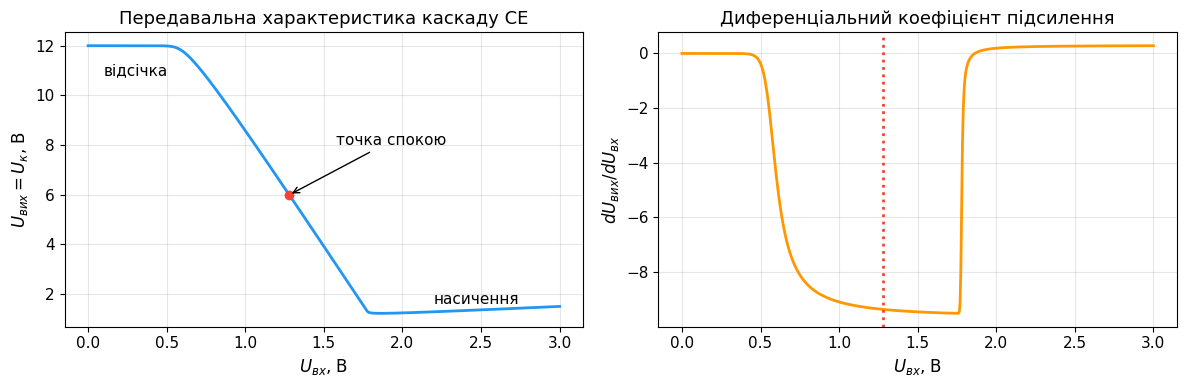

Точка спокою: U_вх = 1.28 В, U_к = 5.99 В;  K_u у точці спокою = -9.36 (оцінка −R_к/R_е = -10.0)


In [7]:
# Передавальна характеристика каскаду СЕ (DC-розгортка), транзистор 2N3904
c = Circuit('CE transfer')
c.include(spice_model('2n3904.lib'))
c.V('cc', 'vcc', c.gnd, 12)
c.V('in', 'src', c.gnd, 0)
c.R('s', 'src', 'b', 1e3)                        # вхід — джерело напруги з внутрішнім опором 1 кОм
c.R('c', 'vcc', 'out', 4.7e3); c.R('e', 'e', c.gnd, 470)
c.BJT(1, 'out', 'b', 'e', model='Q2N3904')
a = c.simulator(temperature=25, nominal_temperature=25).dc(Vin=slice(0, 3, 0.005))
uin = np.array(a.sweep); uout = np.array(a['out'])
k = np.gradient(uout, uin)
i0 = np.argmin(abs(uout - 6.0))                  # точка спокою: U_к = E_ж / 2
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(uin, uout, color='#2196F3'); a1.set_xlabel('$U_{вх}$, В'); a1.set_ylabel('$U_{вих} = U_к$, В')
a1.set_title('Передавальна характеристика каскаду СЕ')
a1.plot(uin[i0], uout[i0], 'o', color='#F44336'); a1.annotate('точка спокою', (uin[i0], uout[i0]), (uin[i0] + 0.3, uout[i0] + 2), arrowprops=dict(arrowstyle='->'))
a1.annotate('відсічка', (0.1, 10.8)); a1.annotate('насичення', (2.2, 1.6))
a2.plot(uin, k, color='#FF9800'); a2.axvline(uin[i0], color='#F44336', ls=':')
a2.set_xlabel('$U_{вх}$, В'); a2.set_ylabel('$dU_{вих}/dU_{вх}$'); a2.set_title('Диференціальний коефіцієнт підсилення')
plt.tight_layout(); plt.show()
print(f'Точка спокою: U_вх = {uin[i0]:.2f} В, U_к = {uout[i0]:.2f} В;  K_u у точці спокою = {k[i0]:.2f} '
      f'(оцінка −R_к/R_е = {-4.7e3/470:.1f})')

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Коефіцієнт гармонік не можна точно визначити «на око» з амплітудної характеристики.** Графічні методи (метод п'яти ординат, порівняння площ) дають лише оцінку. Точне значення отримують вимірюванням спектра (аналізатором спектра або FFT), як у моделі вище. Також пам'ятайте: при малих $K_г$ (до ~10 %) $K_г \approx \sqrt{U_2^2+U_3^2+\ldots}/U_1$, а для великих спотворень іноді нормують до діючого значення *всього* сигналу — це різні величини.

</div>

---

## Енергетичні характеристики підсилювачів <a class="anchor" id="energy"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.4</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Визначати потужність, споживану від джерела живлення, корисну потужність і ККД
> - Пояснювати режими (класи) роботи A, B, AB, C, D через кут відсічки
> - Оцінювати максимальний ККД каскадів класів A і B

</div>

До енергетичних характеристик належать: **споживана потужність** від джерела живлення $P_0 = E_ж I_0$, **корисна (вихідна) потужність** у навантаженні $P_н$, потужність, що розсіюється підсилювальним елементом $P_р = P_0 - P_н$, і **коефіцієнт корисної дії**
$$\eta = \frac{P_н}{P_0}\cdot 100\%.$$

Розрізняють вихідну потужність: **номінальну** (за якої підсилювач тривалий час працює з нормованими спотвореннями), **максимальну** (досяжну короткочасно, зі збільшеними спотвореннями) та **пікову (імпульсну)**.

### Режими (класи) роботи

Клас визначається **кутом відсічки** $\theta$ — половиною тієї частини періоду вхідного сигналу, протягом якої через підсилювальний елемент тече струм:

| Клас | Кут відсічки $\theta$ | Максимальний ККД | Спотворення | Застосування |
|---|---|---|---|---|
| **A** | $180°$ (струм тече весь період) | 25 % (резистивне навантаження), 50 % (трансформатор/дросель) | мінімальні, $K_г < 1\%$ | попередні каскади, Hi-Fi |
| **B** | $90°$ (одна півхвиля) | $\pi/4 \approx 78{,}5\%$ | великі в одному плечі; у двотактній схемі — «сходинка» (перехідні спотворення) | двотактні вихідні каскади |
| **AB** | $90°<\theta<180°$ | 50…70 % | помірні, без «сходинки» | більшість звукових підсилювачів потужності |
| **C** | $<90°$ | до 85…90 % | дуже великі | лише з резонансним навантаженням (передавачі) |
| **D** | ключовий режим (ШІМ) | 90…98 % | визначаються ШІМ і вихідним фільтром | енергоефективні звукові підсилювачі, приводи |

**ККД класу A** (резистивне навантаження в колекторі, синус з амплітудою $U_m \le E_ж/2$):
$$\eta_A = \frac{1}{4}\left(\frac{U_m}{E_ж/2}\right)^2 \le 25\%.$$
**ККД двотактного класу B** (кожне плече живиться від $E_ж$, амплітуда $U_m \le E_ж$):
$$\eta_B = \frac{\pi}{4}\cdot\frac{U_m}{E_ж} \le 78{,}5\%.$$
Важливо, що ККД класу B падає **лінійно** зі зменшенням сигналу, а класу A — **квадратично**; тому в класі A транзистори гріються найбільше саме без сигналу.

**Клас D:** вхідний сигнал перетворюється у послідовність прямокутних імпульсів зі змінною шириною (ШІМ), ключі (MOSFET) працюють тільки в режимах «увімкнено/вимкнено», де втрати мінімальні; корисний сигнал відновлюється LC-фільтром нижніх частот.

---
### 🔬 Інтерактивно: форма струму підсилювального елемента в різних класах <a class="anchor" id="classes-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Змінюйте кут відсічки $\theta$: при 180° — клас A, при 90° — клас B, між ними — AB, менше 90° — клас C. Праворуч — залежність ККД від відносної амплітуди вихідного сигналу для класів A і B.

</div>

In [8]:
# Імпульси струму при куті відсічки θ та ККД класів A і B
def classes(theta=120.0, Um_rel=1.0):
    wt = np.linspace(0, 4 * np.pi, 2000)
    th = np.radians(theta)
    if theta >= 180:
        i = 0.5 + 0.5 * np.cos(wt)          # клас A: струм спокою + змінна складова
        cls = 'A'
    else:
        i = np.maximum(np.cos(wt) - np.cos(th), 0) / (1 - np.cos(th))
        cls = 'B' if abs(theta - 90) < 1 else ('AB' if theta > 90 else 'C')
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
    a1.plot(np.degrees(wt), np.cos(wt), 'k--', lw=1, label='вхідний сигнал')
    a1.plot(np.degrees(wt), i, color='#F44336', label='струм елемента')
    a1.set_xticks(range(0, 721, 90)); a1.set_xlabel('ωt, град'); a1.set_title(f'θ = {theta:.0f}° — клас {cls}'); a1.legend(loc='lower right', fontsize=9)
    x = np.linspace(0, 1, 100)
    a2.plot(x * 100, 25 * x ** 2, color='#2196F3', label='клас A (резистивне навантаження)')
    a2.plot(x * 100, 50 * x ** 2, color='#2196F3', ls='--', label='клас A (трансформатор)')
    a2.plot(x * 100, 78.5 * x, color='#4CAF50', label='клас B (двотактний)')
    a2.axvline(Um_rel * 100, color='#FF9800', ls=':')
    a2.set_xlabel('$U_m / U_{m.max}$, %'); a2.set_ylabel('η, %'); a2.set_title('ККД від рівня сигналу'); a2.legend(fontsize=9)
    plt.tight_layout(); plt.show()
    print(f'При Um = {Um_rel*100:.0f} % від максимуму: η_A = {25*Um_rel**2:.1f} % (резист.), η_B = {78.5*Um_rel:.1f} %')

interact(classes,
         theta=widgets.FloatSlider(min=30, max=180, step=5, value=120, description='θ (град)'),
         Um_rel=widgets.FloatSlider(min=0.05, max=1, step=0.05, value=1, description='Um/Um.max'));

interactive(children=(FloatSlider(value=120.0, description='θ (град)', max=180.0, min=30.0, step=5.0), FloatSl…

---

## Імпульсні і перехідні характеристики підсилювачів <a class="anchor" id="transient"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.5</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснити зміст перехідної та імпульсної характеристик підсилювача
> - Визначати час затримки, час наростання (фронту), викид, час встановлення, спад вершини
> - Пов'язувати параметри перехідної характеристики з граничними частотами АЧХ

</div>

Якість підсилення **імпульсних** сигналів зручніше оцінювати в часовій області.

- **Імпульсна характеристика** $g(t)$ — реакція підсилювача на дельта-функцію $\delta(t)$ (нескінченно короткий імпульс одиничної площі).
- **Перехідна характеристика** $h(t)$ — реакція на одиничний стрибок $1(t)$; практично її знімають, подаючи прямокутні імпульси.

Вони пов'язані з комплексним коефіцієнтом підсилення перетворенням Лапласа: $g(t) = \mathcal L^{-1}\{K(p)\}$, $\;h(t) = \mathcal L^{-1}\{K(p)/p\}$, $\;g(t) = dh/dt$. Зазвичай перехідну характеристику **нормують**: $h_н(t) = h(t)/K_0$.

### Параметри перехідної характеристики

**Область малих часів** (фронт імпульсу; визначається верхньою граничною частотою $f_в$):
- **час затримки** $t_з$ — від моменту стрибка до досягнення рівня 0,5 (іноді 0,1);
- **час наростання (фронту)** $t_ф$ — час зростання від 0,1 до 0,9 усталеного значення;
- **викид** $\delta = \dfrac{h_{max} - h_{уст}}{h_{уст}}\cdot100\%$ — перерегулювання фронту;
- **час встановлення** $t_{вст}$ — від стрибка до моменту, після якого відхилення від усталеного значення не перевищує заданого $\Delta$ (1…5 %).

**Область великих часів** (вершина імпульсу; визначається нижньою граничною частотою $f_н$):
- **спад вершини** $\Delta$ — відносне зменшення вихідної напруги за тривалість імпульсу $t_і$ (через перезаряд розділювальних конденсаторів).

**Зв'язок з частотними характеристиками** (для ланок першого порядку):
$$t_ф \approx 2{,}2\,\tau_в = \frac{2{,}2}{2\pi f_в} \approx \frac{0{,}35}{f_в},\qquad \Delta \approx \frac{t_і}{\tau_н} = 2\pi f_н\,t_і .$$
Отже, щоб передати короткий фронт, потрібна висока $f_в$, а щоб передати довгий імпульс без спаду вершини — низька $f_н$ (в ідеалі ППС, $f_н = 0$). Підсилювач, АЧХ якого має підйом на верхніх частотах (наприклад, через надмірну корекцію або два близькі полюси), дає **викид** на фронті.

---
### 🔬 Інтерактивно: перехідна характеристика і передача прямокутного імпульсу <a class="anchor" id="step-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Модель: два полюси на верхніх частотах (власна частота $f_0$, коефіцієнт загасання $\zeta$) і одна ланка ФВЧ ($f_н$). Зменшуйте $\zeta$ — з'являється викид і коливання; збільшуйте $f_н$ — збільшується спад вершини імпульсу. На графіку відмічено $t_ф$ (0,1…0,9) та викид.

</div>

In [9]:
# Перехідна характеристика: ВЧ-ланка 2-го порядку (f0, ζ) + НЧ-ланка (fн); вхід — прямокутний імпульс
def step_resp(f0_kHz=100.0, zeta=0.7, fn=20.0, ti_us=200.0):
    w0 = 2 * np.pi * f0_kHz * 1e3; wn = 2 * np.pi * fn
    # K(p) = p/(p+wn) * w0^2/(p^2 + 2ζw0 p + w0^2)
    num = [w0 ** 2, 0]
    den = np.polymul([1, wn], [1, 2 * zeta * w0, w0 ** 2])
    sys_ = signal.lti(num, den)
    T = 3 * ti_us * 1e-6
    t = np.linspace(0, T, 6000)
    u = ((t > 0.02 * T) & (t < 0.02 * T + ti_us * 1e-6)).astype(float)
    _, y, _ = signal.lsim(sys_, u, t)
    ts, h = signal.step(signal.lti([w0 ** 2], [1, 2 * zeta * w0, w0 ** 2]), T=np.linspace(0, max(5, 1.2 / zeta) / (f0_kHz * 1e3), 3000))
    i1 = np.argmax(h >= 0.1); i9 = np.argmax(h >= 0.9)
    tf = ts[i9] - ts[i1]; over = max(h.max() - 1, 0) * 100
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.plot(ts * 1e6, h, color='#2196F3')
    a1.axhline(1, color='k', lw=0.8); a1.axhline(0.1, color='#FF9800', ls=':'); a1.axhline(0.9, color='#FF9800', ls=':')
    a1.axvspan(ts[i1] * 1e6, ts[i9] * 1e6, color='#FF9800', alpha=0.2, label=f'$t_ф$ = {tf*1e6:.2f} мкс')
    a1.set_xlabel('t, мкс'); a1.set_ylabel('$h_н(t)$'); a1.set_title(f'Фронт: викид δ = {over:.1f} %'); a1.legend()
    a2.plot(t * 1e6, u, 'k--', lw=1, label='вхід'); a2.plot(t * 1e6, y, color='#F44336', label='вихід')
    t_end = 0.02 * T + ti_us * 1e-6; k_end = np.argmin(abs(t - t_end)) - 1
    a2.set_xlabel('t, мкс'); a2.set_title(f'Імпульс {ti_us:.0f} мкс: спад вершини Δ = {(1 - y[k_end]) * 100:.1f} %'); a2.legend()
    plt.tight_layout(); plt.show()
    fv = f0_kHz * 1e3 * np.sqrt(1 - 2 * zeta**2 + np.sqrt(4 * zeta**4 - 4 * zeta**2 + 2))
    print(f'Верхня гранична частота fв = {fv/1e3:.1f} кГц;  0,35/fв = {0.35/fv*1e6:.2f} мкс  (модель: tф = {tf*1e6:.2f} мкс)')
    print(f'Оцінка спаду вершини 2π·fн·tі = {2*np.pi*fn*ti_us*1e-6*100:.1f} %')

interact(step_resp,
         f0_kHz=widgets.FloatSlider(min=20, max=500, step=10, value=100, description='f₀ (кГц)'),
         zeta=widgets.FloatSlider(min=0.15, max=1.5, step=0.05, value=0.7, description='ζ'),
         fn=widgets.FloatSlider(min=1, max=200, step=1, value=20, description='fн (Гц)'),
         ti_us=widgets.FloatSlider(min=50, max=1000, step=10, value=200, description='tі (мкс)'));

interactive(children=(FloatSlider(value=100.0, description='f₀ (кГц)', max=500.0, min=20.0, step=10.0), FloatS…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Час наростання визначається верхньою, а спад вершини — нижньою граничною частотою, а не навпаки.** Широка смуга «вгору» потрібна, щоб передати крутий фронт; низька $f_н$ — щоб утримати плоску вершину довгого імпульсу. Тому ППС (з $f_н = 0$) передає вершину будь-якої тривалості без спаду.

</div>

---
### ⚡ Практичне застосування: вибір підсилювача за параметрами

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Задача | Ключові вимоги | Приклад |
|---|---|---|
| Мікрофонний попередній підсилювач | малий шум першого каскаду, $K_u = 40\ldots60$ дБ, $f = 20$ Гц…20 кГц | малошумний ОП (NE5532), дискретний каскад на польових транзисторах |
| Вихідний каскад звукового підсилювача | $P_н$ = десятки Вт, $K_г < 0{,}1\%$, високий ККД | двотактний клас AB або клас D |
| Підсилювач осцилографа | плоска АЧХ до сотень МГц, мінімальний викид | широкосмуговий каскад з корекцією (тема 4) |
| Тензометричний / термопарний вхід | $f_н = 0$, малий дрейф нуля, великий КПСС | вимірювальний ППС (теми 6, 8) |
| Передавач | висока потужність і ККД на одній частоті | клас C з резонансним навантаженням |

</div>

---
### ✅ Питання для самоперевірки: параметри та характеристики підсилювачів

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Звідки береться енергія підсиленого сигналу?</summary>

> **Відповідь:** З джерела живлення. Вхідний сигнал лише керує підсилювальним елементом, який дозує потік енергії від $E_ж$ до навантаження.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чому підсилювач напруги повинен мати великий вхідний і малий вихідний опір?</summary>

> **Відповідь:** Великий $R_{вх}$ мінімізує падіння напруги на внутрішньому опорі джерела сигналу (вхідний подільник $R_{вх}/(R_c+R_{вх}) \to 1$), малий $R_{вих}$ — падіння напруги на самому підсилювачі при підключенні навантаження ($R_н/(R_{вих}+R_н) \to 1$).

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Що таке нижня і верхня граничні частоти?</summary>

> **Відповідь:** Частоти, на яких коефіцієнт підсилення зменшується у $\sqrt2$ разів (на 3 дБ) відносно $K_0$; між ними лежить смуга пропускання.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Які гармоніки з'являються при симетричному обмеженні сигналу?</summary>

> **Відповідь:** Переважно непарні (3-тя, 5-та, …). Парні гармоніки свідчать про асиметрію амплітудної характеристики.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому ККД класу B вищий, ніж класу A?</summary>

> **Відповідь:** У класі B струм спокою практично відсутній: транзистор проводить лише одну півхвилю, тож споживання пропорційне сигналу. Максимальний ККД $\pi/4 \approx 78{,}5\%$ проти 25…50 % у класі A.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Як пов'язані час наростання і верхня гранична частота?</summary>

> **Відповідь:** Для ланки першого порядку $t_ф \approx 0{,}35/f_в$: чим ширша смуга, тим крутіший фронт.

</details>

---
### 📝 Задачі для самостійного розв'язання: параметри підсилювачів


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Підсилювач має $K_{u0} = 200$, $R_{вх} = 20$ кОм, $R_{вих} = 500$ Ом. Джерело сигналу — $E_c = 10$ мВ, $R_c = 5$ кОм; навантаження $R_н = 2$ кОм. Знайдіть наскрізний коефіцієнт підсилення, вихідну напругу і коефіцієнт підсилення за потужністю.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $K_{скв} = 200\cdot\dfrac{20}{25}\cdot\dfrac{2}{2{,}5} = 128$ (42,1 дБ); $U_{вих} = 1{,}28$ В. $U_{вх} = 8$ мВ, $K_u = 160$; $K_i = \dfrac{U_{вих}/R_н}{U_{вх}/R_{вх}} = 160\cdot\dfrac{20}{2} = 1600$; $K_p = K_u K_i = 2{,}56\cdot10^5$ (54,1 дБ).

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Каскад має $f_н = 30$ Гц і $f_в = 50$ кГц. Яким буде коефіцієнт частотних спотворень $M_н$ на частоті 15 Гц (модель першого порядку) і час наростання фронту?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $M_н = \sqrt{1 + (f_н/f)^2} = \sqrt{1 + 4} = 2{,}24$ (7 дБ). $t_ф \approx 0{,}35/f_в = 7$ мкс.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Підсилювач класу B з $E_ж = \pm 20$ В працює на навантаження 8 Ом з амплітудою вихідної напруги 16 В. Знайдіть $P_н$, ККД та потужність, що розсіюється транзисторами.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $P_н = U_m^2/(2R_н) = 16$ Вт; $\eta = \dfrac{\pi}{4}\cdot\dfrac{16}{20} = 62{,}8\%$; $P_0 = P_н/\eta = 25{,}5$ Вт; на обох транзисторах розсіюється $\approx 9{,}5$ Вт.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Поняття | Формула / зміст |
|---|---|
| Коефіцієнти підсилення | $K_u = U_{вих}/U_{вх}$, $K_i = I_{вих}/I_{вх}$, $K_p = K_uK_i$ |
| Децибели | $20\lg K_u$, $20\lg K_i$, $10\lg K_p$ |
| Наскрізне підсилення | $K_{скв} = \dfrac{R_{вх}}{R_c+R_{вх}}K_{u0}\dfrac{R_н}{R_{вих}+R_н}$ |
| Граничні частоти | $K(f_{н,в}) = K_0/\sqrt2$ (−3 дБ) |
| Динамічний діапазон | $D = 20\lg(U_{вх.max}/U_{вх.min})$ |
| Коефіцієнт гармонік | $K_г = \sqrt{\sum_{k\ge2}U_k^2}\,/\,U_1$ |
| ККД | $\eta = P_н/P_0$; $\eta_{A} \le 25$ (50) %, $\eta_B \le 78{,}5$ % |
| Перехідна характеристика | $t_ф \approx 0{,}35/f_в$, $\Delta \approx 2\pi f_н t_і$ |

**Головні висновки.** Підсилювач — керований перетворювач енергії джерела живлення. Його якість описують частотні (АЧХ, ФЧХ), амплітудна, енергетичні та перехідна характеристики, які взаємопов'язані: смуга пропускання визначає форму фронту і вершини імпульсу, кривизна амплітудної характеристики — нелінійні спотворення, клас роботи — компроміс між ККД і лінійністю.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Павлов В. Н., Ногин В. Н. Схемотехника аналоговых электронных устройств. — М.: Горячая линия – Телеком, 2003.
7. Self D. Audio Power Amplifier Design. — 6th ed. — Focal Press, 2013.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">[Тема 2. Багатокаскадні підсилювачі. Зворотний зв'язок і стійкість](Тема_02_Багатокаскадні_підсилювачі_та_зворотний_звязок.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*